In [33]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# import nested_pandas as npd

%matplotlib inline

In [34]:
from rubin_sim.maf.metrics.grb_afterglows_metrics import (
    GRBAfterglowMetric
)
from rubin_sim.maf import slicers
from rubin_sim.maf import metricBundles
from rubin_sim.maf import db

In [3]:
from redback import model_library
from lightcurvelynx.models.redback_models import RedbackWrapperModel
from lightcurvelynx.math_nodes.ra_dec_sampler import ObsTableRADECSampler


from lightcurvelynx.obstable.opsim import OpSim
from lightcurvelynx.survey_info import SurveyInfo
from lightcurvelynx.math_nodes.np_random import NumpyRandomFunc
from lightcurvelynx.simulate import (
    compute_single_noise_free_lightcurve,
    simulate_lightcurves,
)
from lightcurvelynx.utils.post_process_results import results_augment_lightcurves, results_drop_empty
from lightcurvelynx.utils.plotting import plot_lightcurves
from lightcurvelynx.graph_state import GraphState
from lightcurvelynx.math_nodes.ra_dec_sampler import (
    ApproximateMOCSampler)

15:48 redback WARNING : No module named 'lalsimulation'
15:48 redback WARNING : lalsimulation is not installed. Some EOS based models will not work. Please use bilby eos or pass your own EOS generation class to the model
15:48 bilby INFO    : Running bilby version: 2.8.2
15:48 redback INFO    : Running redback version: 1.20.0


## Running GRB Afterglows Metrics with MAF and LightCurveLynx

This notebook walks through simulating GRB Afterglows with LightCurveLynx and using that output to compute the MAF GRB Afterglows metrics.

There are two GRB Afterglows metrics, and they are in one class. 

Recognize metric: Requires two observations in different filters within 12 hours AND two observations in THE SAME filters showing magnitude change.

Spectroscopically triggerable metric: events are flagged as spectroscopically triggerable if they reach at least mag 21 in any filter.

The GRB Afterglows metrics use the GRB Afterglows model built in to Redback (wrapped in Lynx) and the Lynx slicer that reads Lynx output. This notebook begins with creating the Lynx output.

## Simulating Afterglows in LightCurveLynx

First, we set up the opsim for LCL:

In [4]:
opsim_url = "https://s3df.slac.stanford.edu/data/rubin/sim-data\
    /sims_featureScheduler_runs5.3/baseline/baseline_v5.3.0_10yrs.db"

# Uncomment the following line to load data from a URL
ops_data = OpSim.from_url(opsim_url, use_detector_footprint="lsst")

# Alternatively if you are using a local OpSim with a known file path,
# you can use from_db() or from_parquet() to read it directly.

In [5]:
ops_data.head()

,observationId,ra,dec,time,flush_by_mjd,exptime,band,filter,rotation,rotSkyPos_desired,...,moonDistance,solarElong,moonPhase,cummTelAz,observation_reason,science_program,cloud_extinction,zp,psf_footprint,sky_bg_e
0,0,266.377911,-45.894524,61208.201382,61208.255938,38.0,u,u,278.404669,0.0,...,147.083478,157.452826,16.210877,-179.137913,template_blob_uu_25.0,BLOCK-419,0.0,2.386006,41.765721,50.658052
1,1,262.574865,-46.941452,61208.201933,61208.255938,38.0,u,u,289.642367,0.0,...,144.274292,156.323709,16.216452,-170.506774,template_blob_uu_25.0,BLOCK-419,0.0,2.393835,42.140785,50.507657
2,2,266.039362,-49.016651,61208.202483,61208.255938,38.0,u,u,279.140130,0.0,...,145.200492,154.341310,16.222024,-179.031250,template_blob_uu_25.0,BLOCK-419,0.0,2.404088,42.630972,50.274301
3,3,261.992377,-50.037844,61208.203025,61208.255938,38.0,u,u,289.266344,0.0,...,142.425648,153.203529,16.227522,-171.793078,template_blob_uu_25.0,BLOCK-419,0.0,2.413818,43.095059,50.145802
4,4,265.679819,-52.132077,61208.203568,61208.255938,38.0,u,u,279.725930,0.0,...,143.183649,151.231294,16.233029,-179.147649,template_blob_uu_25.0,BLOCK-419,0.0,2.426261,30.840128,49.924925


In [6]:
survey_info = SurveyInfo(obstable=ops_data, survey_name="LSST")

We're only going to simulate GRB Afterglows in the region of the sky that is accessible by the LSST, so we ufeed the obs table into our RA and dec sampler

In [7]:
ra_dec_sampler = ObsTableRADECSampler(
    ops_data,
    radius=3.0,  # degrees - not sure what a good choice is here
    node_label="ra_dec_sampler",
)

### Create Parameter Distributions

The GRB Afterglows model has built-in priors from redback but their file loading system is broken right now, so we are copying them down manually.

We must choose the total number of grb afterglows, which for now will be 10. Later it will be more :)

We use obs_time_window_offset to only simulate grb afterglows during their lifetime, to avoid the unnecessary computation of simulating the sky background for the other 9.99 years. 

In [13]:
parameters = {
    "base_model": "tophat",

    # Source properties
    "redshift": NumpyRandomFunc("uniform", low=0.01, high=3),
    "thv": NumpyRandomFunc("uniform", low=0.0, high=0.2),  #SHOULD BE SINE FUNCTION    # viewing angle [rad] $originally .5
    "loge0": NumpyRandomFunc("uniform", low=52.0, high=54.0),  # log10 E_iso [erg] #was 44 or something
    "logn0": NumpyRandomFunc("uniform", low=-5, high=2),   # log10 ISM density [cm^-3]
    "thc": NumpyRandomFunc("uniform", low=0.01, high=0.1)  ,                                            # jet half-opening angle [rad]
    "p": NumpyRandomFunc("uniform", low=2, high=3)  ,
    "logepse": NumpyRandomFunc("uniform", low=-2, high=0)  , #was -5
    "logepsb": NumpyRandomFunc("uniform", low=-5, high=0)  ,
    "ksin": NumpyRandomFunc("uniform", low=0, high=1)  ,
    "g0": NumpyRandomFunc("uniform", low=100, high=2000)  
}

In [14]:
# peak times - random throughout whole survey
peak_time_sampler = NumpyRandomFunc(
    "uniform", low=np.min(ops_data["time"]), high=np.max(ops_data["time"])
)

In [15]:
rb_model_metadata = model_library.get_model_metadata(
    "tophat_redback",
    default=None,)

In [16]:
rb_model = model_library.all_models_dict["afterglow_models_sed"]

In [17]:
# Create the Lynx model from the Redback model.
model = RedbackWrapperModel(
    rb_model,
    parameters=parameters,  # Set ALL the redback model parameters
    ra=ra_dec_sampler.ra,  # Set other parameters
    dec=ra_dec_sampler.dec,
    t0=peak_time_sampler,
    node_label="source",
    # time_extrapolation=(ConstantPadding(0.0), ConstantPadding(0.0)),
    model_metadata=rb_model_metadata,
)

In [61]:
# Fix the random seed to make it reproducible.
rng = np.random.default_rng(42)

#choose your number of afterglows to simulate
num_samples=100

#simulate
df = simulate_lightcurves(
    model=model,
    num_samples=num_samples,
    survey_info=survey_info,
    rng=rng,
    obs_time_window_offset=(0, 20), 
    drop_empty_rows=True,  # Drop objects we don't see at all.
)

# if you want to view df,
# keep params separate because it is quite large:
# params = df["params"].copy()
# df = df_1.drop(columns=["params"])

# to view params as an astropy table:
# state = GraphState.from_list(params)
# params_table = state.to_table()

Simulating: 100%|███████████████████████████| 100/100 [04:50<00:00,  2.91s/obj]


First, let's check how many were observed within our time window:

In [62]:
print("total number: ",len(df))
print("fraction within time window: ", len(df)/num_samples)

total number:  54
fraction within time window:  0.54


Now let's also filter out a couple more things, before we get to the time-consuming step of the calculation:
- anything with an snr of <5 (we would filter this out in the metric later anyway)


In [63]:
#add snr column
aug = results_augment_lightcurves(df, min_snr=5)

#mask by SNR (too-low SNR sets detection=False)
detect_mask = aug["lightcurve"]['detection']
aug["lightcurve"] = aug["lightcurve"][detect_mask]

#drop empty rows
aug = results_drop_empty(aug)
params = aug["params"].copy()
aug.drop(columns=["params"], inplace=True)

print("total number that made it through filtering: ",len(aug))
print("fraction of all grb afterglows: ", len(aug)/num_samples)

total number that made it through filtering:  8
fraction of all grb afterglows:  0.08


And we can look at a couple of them. It will become obvious that not all of these have been detected in a useable way, which is why the MAF metric is a necessary step.

In [64]:
plt.rcParams['text.usetex'] = False

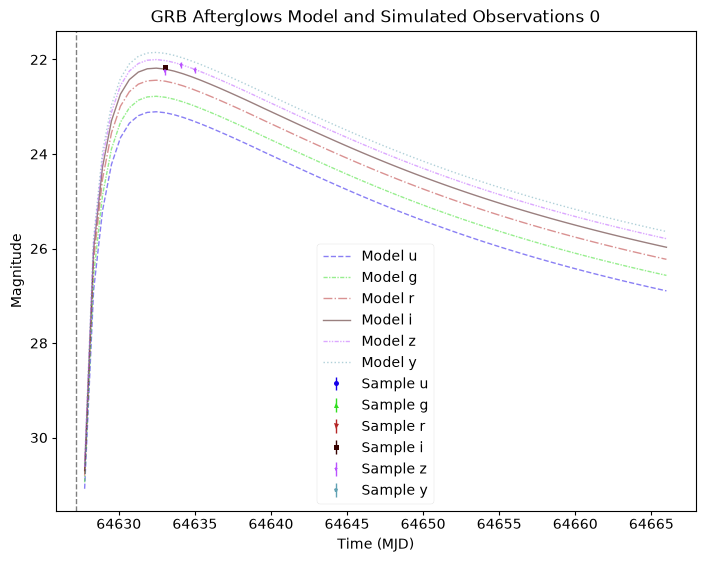

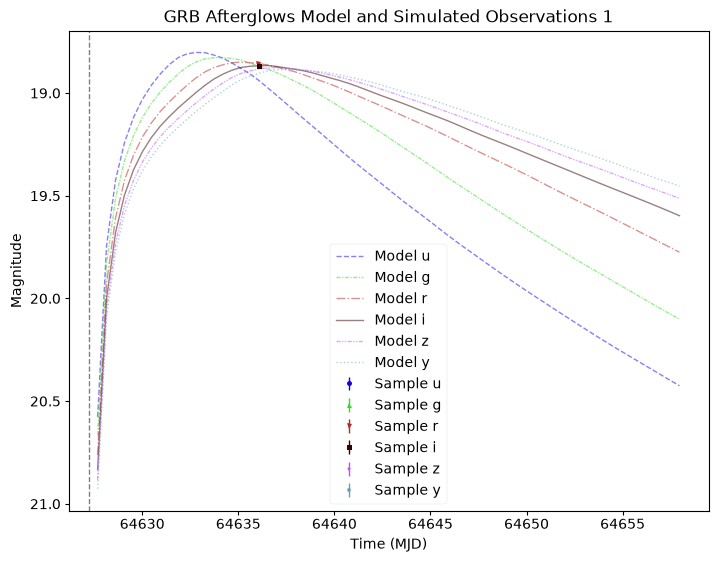

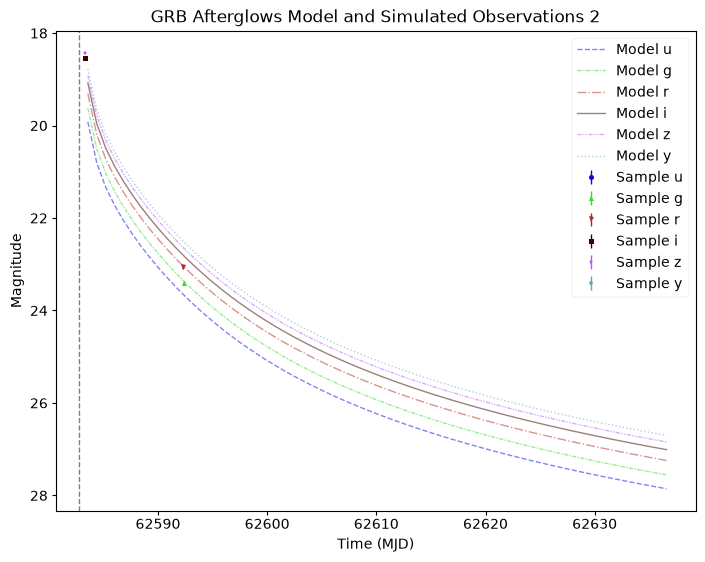

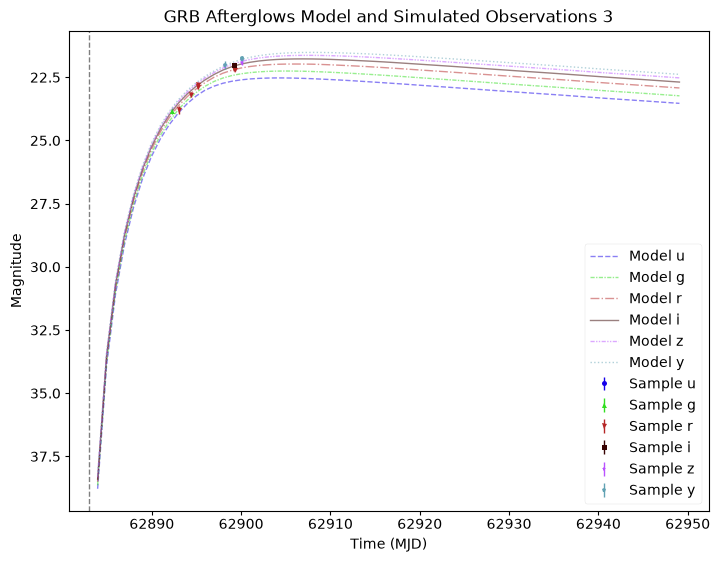

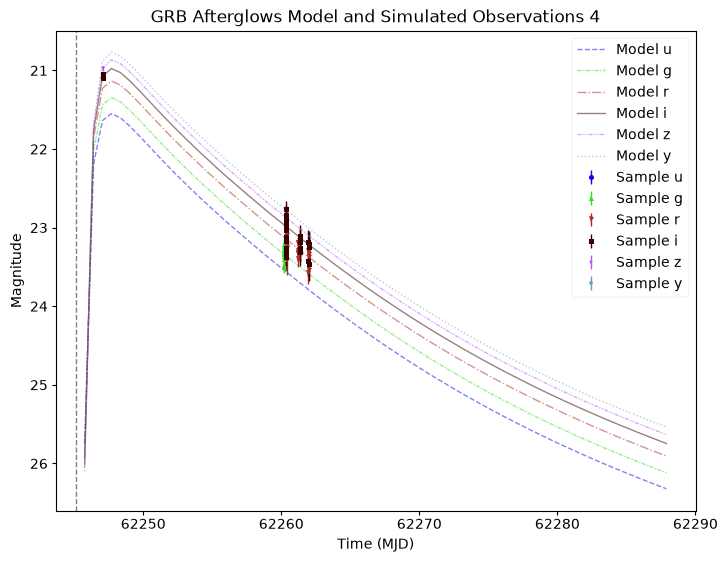

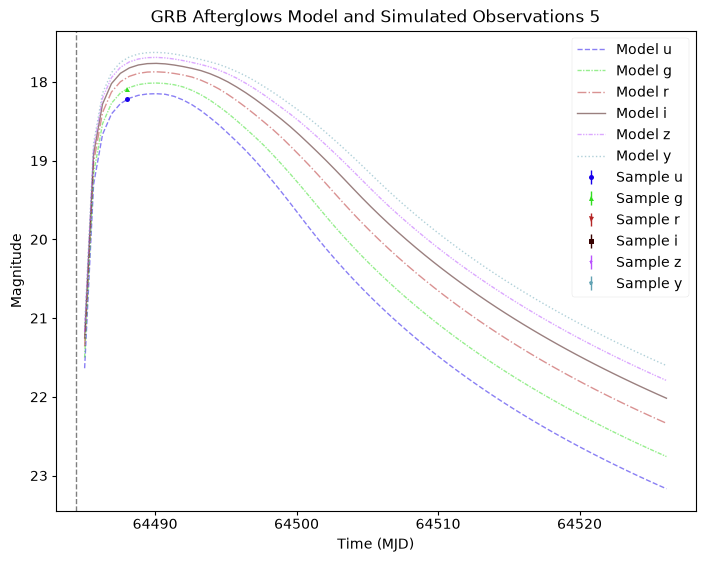

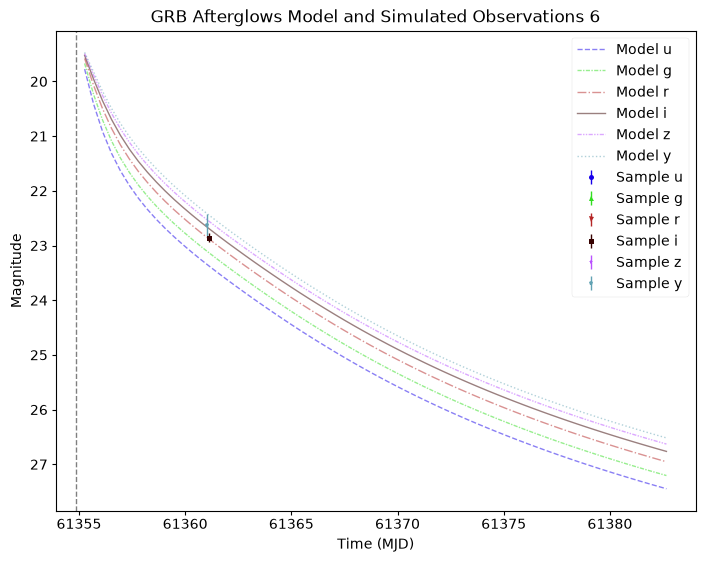

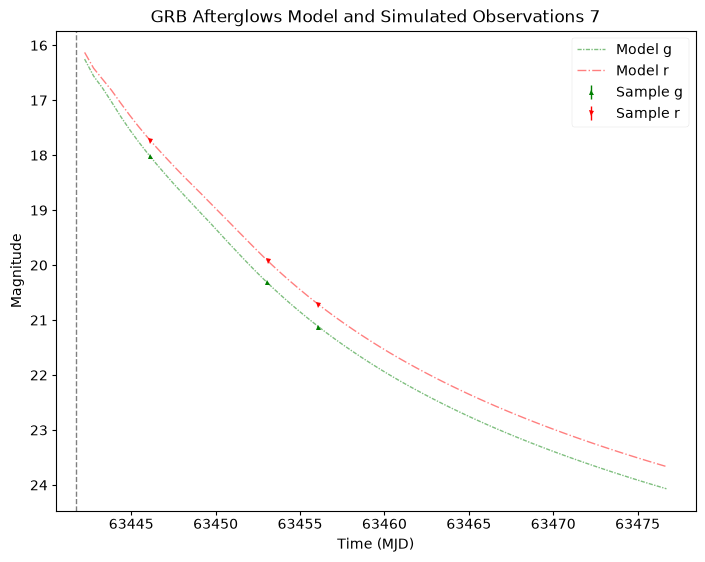

In [83]:

for i in range(8):
    idx = i #first one with observations #aug.iloc[i]['id'] if you don't do results_drop_empty
    # Extract the row for this object.
    row = aug.loc[idx]
    lc = row["lightcurve"]

    # Extract the parameters used during the simulation of this object. Use that to
    # compute the noise-free light curve for this object, which we will plot alongside
    # the simulated light curve.
    noise_free_lcs = compute_single_noise_free_lightcurve(
        model,
        GraphState.from_dict(params[idx]),
        survey_info.passbands,
        rest_frame_phase_min=0,
        rest_frame_phase_max=20,
        rest_frame_phase_step=0.3,
    )

    plot_lightcurves(
        fluxes=lc["flux"],
        times=lc["mjd"],
        fluxerrs=lc["fluxerr"],
        filters=lc["filter"],
        underlying_model=noise_free_lcs,
        plot_magnitudes=True,
    )

    # Plot a vertical line at t0, which is the reference time for the light curve.
    plt.axvline(
        x=params[idx]["source.t0"], color="k", linestyle="--", alpha=0.5
    )
    # plt.xlim(params[idx]["MDwarfFlareModel_0.t0"]-10, params[idx]["MDwarfFlareModel_0.t0"]+15)
    # plt.ylim(29,22)
    plt.title("GRB Afterglows Model and Simulated Observations " + str(idx))
    plt.legend()
    plt.show()

Now we save the lc and the files for loading into MAF.

In [66]:
YOUR_DATA_PATH = "/Users/wickcedar/maf_runs/"

In [67]:
aug.to_parquet(os.path.join(YOUR_DATA_PATH, "my_results_grb.parquet"))
params.to_csv(os.path.join(YOUR_DATA_PATH, "my_params_grb.csv"))

## Running MAF on the LCL output

We will use this function which uses the LynxBaseSlicer to handle the parquet file. Results are written to your data path.

In [45]:
def run_lightcurvelynx(sim_data, metric):
    out_dir = YOUR_DATA_PATH
    slicer = slicers.lynx_slicer.LynxResultsSlicer()
    metric = metric(col="lightcurve", from_results=True)

    bundle = metricBundles.MetricBundle(metric, slicer, constraint="")

    results_db = db.ResultsDb(out_dir=out_dir)

    group = metricBundles.MetricBundleGroup(
        [bundle],
        sim_data,
        out_dir=out_dir,
        results_db=results_db,
        db_table="lightcurves",
    )

    group.run_all()

In [73]:
run_lightcurvelynx(
    os.path.join(YOUR_DATA_PATH, "my_results_grb.parquet"), mm.GRBAfterglowMetric
) 

Your results will live in your data path as well. Let's see how many events met our metric criteria:

In [74]:
results_file = np.load(
    os.path.join(YOUR_DATA_PATH, "run_name_GRBAfterglow_lightcurve_LYNX.npz"),
    allow_pickle=True
)

In [75]:
pd.DataFrame(list(results_file["metric_values"])) 

,metric_value_recognize,metric_value_spectrig
0,False,False
1,False,False
2,False,False
3,True,False
4,True,False
5,False,False
6,False,False
7,True,False


In [79]:
print("Number of recognized GRB Afterglows: ",
      np.sum(pd.DataFrame(list(results_file["metric_values"])) ["metric_value_recognize"]))
print("Number of spectroscopically triggerable GRB Afterglows: ",
      np.sum(pd.DataFrame(list(results_file["metric_values"])) ["metric_value_spectrig"]))


Number of recognized GRB Afterglows:  3
Number of spectroscopically triggerable GRB Afterglows:  0


In [80]:
good_indices = np.where(pd.DataFrame(list(results_file["metric_values"])) ["metric_value_recognize"])[0]

You can view the params associated with an observation by indexing your previously-saved params

In [43]:
my_params = pd.read_csv(os.path.join(YOUR_DATA_PATH, "my_params.csv"))

In [85]:
# Use this to check out the light curve if you want
aug.loc[good_indices]['lightcurve']
# and the params:
# my_params.loc[np.where(results_file['metric_values'])[0][0]]['params']

3    [{mjd: 62892.259282, filter: 'g', flux: 1069.4...
4    [{mjd: 62247.055765, filter: 'z', flux: 14820....
7    [{mjd: 63446.103228, filter: 'g', flux: 225948...
Name: lightcurve, dtype: nested<mjd: [double], filter: [large_string], flux: [double], fluxerr: [double], flux_perfect: [double], survey_idx: [int64], obs_idx: [int64], is_saturated: [bool], snr: [double], detection: [bool], mag: [double], magerr: [double], time_rel: [double]>

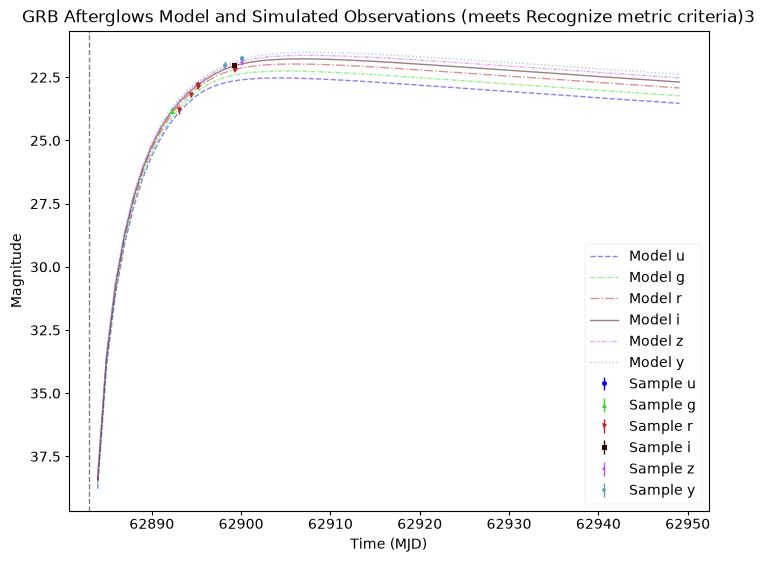

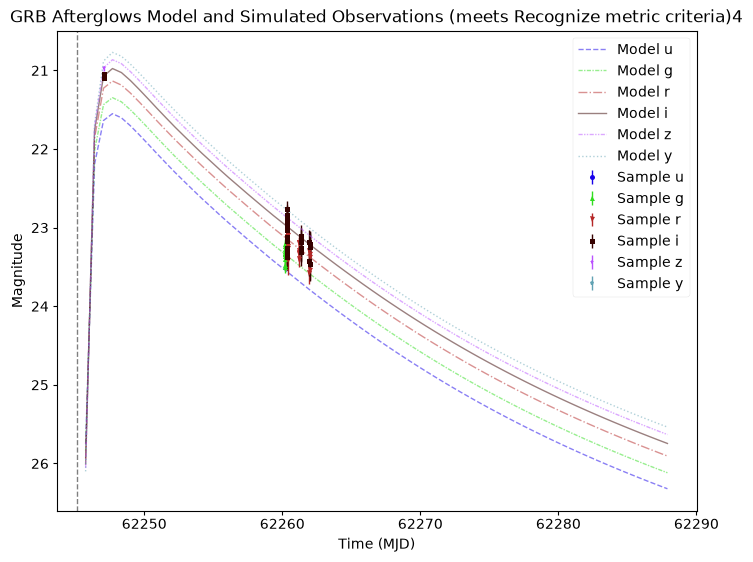

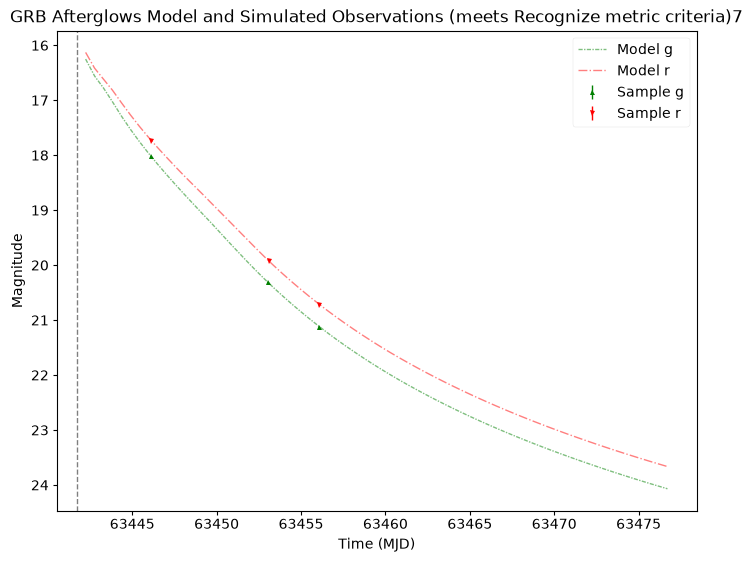

In [87]:
for i in good_indices:
    idx = i
    # Extract the row for this object.
    row = aug.loc[idx]
    lc = row["lightcurve"]

    # Extract the parameters used during the simulation of this object. Use that to
    # compute the noise-free light curve for this object, which we will plot alongside
    # the simulated light curve.
    noise_free_lcs = compute_single_noise_free_lightcurve(
        model,
        GraphState.from_dict(params[idx]),
        survey_info.passbands,
        rest_frame_phase_min=0,
        rest_frame_phase_max=20,
        rest_frame_phase_step=0.3,
    )

    plot_lightcurves(
        fluxes=lc["flux"],
        times=lc["mjd"],
        fluxerrs=lc["fluxerr"],
        filters=lc["filter"],
        underlying_model=noise_free_lcs,
        plot_magnitudes=True,
    )

    # Plot a vertical line at t0, which is the reference time for the light curve.
    plt.axvline(
        x=params[idx]["source.t0"], color="k", linestyle="--", alpha=0.5
    )
    # plt.xlim(params[idx]["MDwarfFlareModel_0.t0"]-10, params[idx]["MDwarfFlareModel_0.t0"]+15)
    # plt.ylim(29,22)
    plt.title("GRB Afterglow Model and Simulated Observations (meets Recognize metric criteria) " + str(idx))
    plt.legend()
    plt.show()